In [9]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KDTree

galaxy = pd.read_csv(
    "results/galaxy_coordinates.csv.gz",
    dtype={"specObjID": "string"},
)

joint = pd.read_csv("../comparison/results/joint_summary.csv")

cases = pd.DataFrame({
    "case": ["om_low", "om_best", "om_high"],
    "Omega_m": [
        joint.loc[0, "lower_68"],
        joint.loc[0, "Omega_m"],
        joint.loc[0, "upper_68"],
    ],
})

cases

,case,Omega_m
0,om_low,0.296391
1,om_best,0.304000
2,om_high,0.312247


In [10]:
z = galaxy["z"].values
ra = galaxy["ra"].values * np.pi / 180
dec = galaxy["dec"].values * np.pi / 180

assert len(galaxy) > 10
assert np.isfinite(galaxy[["ra", "dec", "z"]].values).all()
assert (z > 0).all()

direction = np.column_stack((
    np.cos(dec) * np.cos(ra),
    np.cos(dec) * np.sin(ra),
    np.sin(dec),
))

z_grid = np.linspace(0, max(z), 10001)
dz = z_grid[1] - z_grid[0]

result = galaxy[["specObjID", "z"]].copy()
timings = []

BATCH_SIZE = 20000

In [11]:
for name, om in zip(cases["case"], cases["Omega_m"]):
    start = time.perf_counter()

    inv_e = 1 / (om * (1 + z_grid)**3 + 1 - om)**0.5

    integral = np.zeros(len(z_grid))
    integral[1:] = np.cumsum((inv_e[:-1] + inv_e[1:]) * dz / 2)

    distance = 2997.92458 * np.interp(z, z_grid, integral)
    xyz = direction * distance.reshape(-1, 1)

    tree = KDTree(xyz)
    r10 = np.zeros(len(galaxy))

    for first in range(0, len(galaxy), BATCH_SIZE):
        last = min(first + BATCH_SIZE, len(galaxy))
        neighbor_distances = tree.query(
            xyz[first:last],
            k=11,
            return_distance=True,
        )[0]

        r10[first:last] = neighbor_distances[:, 10]

    result["distance_" + name] = distance
    result["r10_" + name] = r10

    timings.append({
        "case": name,
        "Omega_m": om,
        "seconds": time.perf_counter() - start,
    })

timing = pd.DataFrame(timings)
timing

,case,Omega_m,seconds
0,om_low,0.296391,0.924663
1,om_best,0.304000,0.908442
2,om_high,0.312247,0.881350


In [13]:
assert (result["r10_om_best"] > 0).all()

for name in ["om_low", "om_high"]:
    for quantity in ["distance", "r10"]:
        result[quantity + "_change_" + name + "_percent"] = 100 * (
            result[quantity + "_" + name]
            / result[quantity + "_om_best"]
            - 1
        )

result.to_csv(
    "results/galaxy_cosmology_sensitivity.csv.gz",
    index=False,
    compression="gzip",
)

cases.to_csv("results/galaxy_cosmology_cases.csv", index=False)
timing.to_csv("results/galaxy_cosmology_timing.csv", index=False)

In [14]:
change_columns = [
    "distance_change_om_low_percent",
    "distance_change_om_high_percent",
    "r10_change_om_low_percent",
    "r10_change_om_high_percent",
]

summary = result[change_columns].describe(
    percentiles=[0.16, 0.5, 0.84]
).T

summary.to_csv("results/galaxy_cosmology_change_summary.csv")

summary[["mean", "16%", "50%", "84%", "min", "max"]]

,mean,16%,50%,84%,min,max
distance_change_om_low_percent,0.059178,0.034068,0.057176,0.085934,0.017111,0.112421
distance_change_om_high_percent,-0.063960,-0.092813,-0.061827,-0.036875,-0.121286,-0.018534
r10_change_om_low_percent,0.080215,0.042882,0.075075,0.117048,0.017123,0.225742
r10_change_om_high_percent,-0.086640,-0.126354,-0.081149,-0.046402,-0.242975,-0.018547


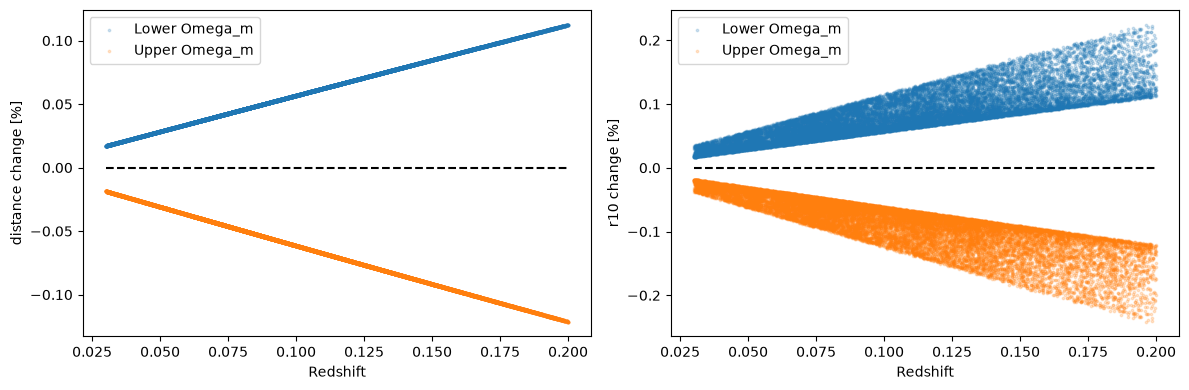

In [15]:
plot_data = result.sample(
    n=min(20000, len(result)),
    random_state=42,
)

plt.figure(figsize=(12, 4))

for i, quantity in enumerate(["distance", "r10"]):
    plt.subplot(1, 2, i + 1)

    for name, label in [
        ("om_low", "Lower Omega_m"),
        ("om_high", "Upper Omega_m"),
    ]:
        plt.scatter(
            plot_data["z"],
            plot_data[quantity + "_change_" + name + "_percent"],
            s=3,
            alpha=0.2,
            label=label,
        )

    plt.plot([min(z), max(z)], [0, 0], "k--")
    plt.xlabel("Redshift")
    plt.ylabel(quantity + " change [%]")
    plt.legend()

plt.tight_layout()
plt.savefig("results/galaxy_cosmology_sensitivity.png", dpi=200)
plt.show()